# **Projekt 1: Klasyfikacja wieloklasowa za pomocą w pełni połączonej sieci neuronowej**

**Przedmiot:** Wstęp do sieci neuronowych

**Wykonali:** Mateusz Panek, Piotr Jasiak

---

# 1. Cel i kontekst projektu

Niniejszy projekt powstał w ramach przedmiotu **„Wprowadzenie do sieci neuronowych”** i ma na celu praktyczne przećwiczenie pełnego pipeline’u budowy w pełni połączonej sieci neuronowej w PyTorchu.

Pracujemy na zbiorze **Dry Bean Dataset**, w którym każda próbka opisuje jedno ziarno fasoli za pomocą **16 cech geometrycznych** (dokładny opis cech geometryczny przedstawiony jest kilka komórek niżej) wyznaczonych z obrazu oraz klasy docelowej (7 odmian fasoli). Na podstawie tych cech chcemy nauczyć sieć neuronową wykonywać **wieloklasową klasyfikację** – czyli przypisywać każdemu ziarnu odpowiedni gatunek.

W ramach projektu:

- przygotowujemy dane (podział na zbiory trening/walidacja/test oraz **standaryzację cech**),
- definiujemy klasę datasetu i DataLoader‑y w PyTorchu (mini‑batch learning),
- implementujemy różne architektury w pełni połączonych sieci (różna liczba warstw, neuronów, funkcji aktywacji),
- trenujemy modele z wykorzystaniem **CrossEntropyLoss** oraz optymalizatorów **SGD/Adam**,
- stosujemy mechanizmy poprawiające generalizację: **L2 (weight decay)**, **dropout**, **early stopping**,
- porównujemy wyniki (dokładność na zbiorze walidacyjnym/testowym, przebieg funkcji straty),
- na końcu wybieramy „najlepszy” model i analizujemy, co w praktyce poprawia/psuje jakość klasyfikacji.

Dodatkowo, aby eksperyment był pełniejszy, będziemy porównywać zachowanie wybranych modeli:

- na danych **ze standaryzacją**,  
- na danych **bez standaryzacji**.

Pozwoli nam to sprawdzić, jak bardzo skalowanie cech wpływa na stabilność treningu i końcową dokładność sieci neuronowych w zadaniu klasyfikacji wieloklasowej.

---

# 2. Potrzebne biblioteki i importy

In [2]:
!pip install ucimlrepo -q
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

# Ustalamy seed dla powtarzalności wyników
torch.manual_seed(515)
np.random.seed(515)

# 3. Analiza cech wejściowych

## 3.1 Szczegółowy opis cech wejściowych
Modele klasyfikują 7 odmian fasoli na podstawie wektora 16 cech geometrycznych pobranych z obrazów (zrobionych zdjęć przez autora zbioru):

1. **Area (A):** Pole powierzchni ziarna wyrażone w liczbie pikseli.
2. **Perimeter (P):** Obwód ziarna.
3. **MajorAxisLength (L):** Długość osi głównej (najdłuższa linia przechodząca przez ziarno).
4. **MinorAxisLength (l):** Długość osi pomocniczej (najkrótsza linia prostopadła do osi głównej).
5. **AspectRatio (K):** Stosunek długości osi głównej do pomocniczej (L/l).
6. **Eccentricity (e):** Mimośród elipsy; określa stopień wydłużenia ziarna.
7. **ConvexArea (C):** Pole powierzchni najmniejszego wielokąta wypukłego zawierającego ziarno.
8. **EquivDiameter (Ed):** Średnica koła o tym samym polu co ziarno.
9. **Extent (Ex):** Stosunek pola ziarna do pola prostokąta otaczającego ziarno.
10. **Solidity (S):** Współczynnik zwartości, stosunek pola powierzchni do pola wypukłego (A/C).
11. **Roundness (R):** Współczynnik kolistości ziarna.
12. **Compactness (CO):** Współczynnik zwartości ziarna, mierzony jako Ed/L.
13. **ShapeFactor1:** Współczynnik nieregularności kształtu (L/A).
14. **ShapeFactor2:** Drugi współczynnik nieregularności kształtu (l/A).
15. **ShapeFactor3:** Trzeci współczynnik kształtu opisujący pole powierzchni.
16. **ShapeFactor4:** Czwarty współczynnik kształtu opisujący odchylenie od elipsy.

**Klasy docelowe (7):** Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira.

## 3.2 Przygotowanie danych (standaryzacja/bez standaryzacji)

In [ ]:
# Wczytanie zbioru Dry Bean z pliku Excel
dry_bean = pd.read_excel("data/dry_bean_dataset.xlsx")

# Podział na cechy i etykiety
X = dry_bean.drop(columns=["Class"])   # 16 cech wejściowych
y = dry_bean["Class"]                  # etykiety klas (7 odmian fasoli)

# Label Encoding: zamiana etykiet tekstowych na liczby całkowite (0–6)
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y.values.ravel())

# Podział danych: 70% trening, 15% walidacja, 15% test (ze stratyfikacją)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Wariant 1: dane bez standaryzacji

# Zapisujemy kopię danych przed skalowaniem – jako numpy arrays
X_train_raw = X_train.values
X_val_raw   = X_val.values
X_test_raw  = X_test.values

# Wariant 2: dane ze standaryzacją

# Standaryzacja: przesunięcie średniej do 0 i odchylenia standardowego do 1
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# Dataset w formacie kompatybilnym z PyTorchem
class BeanDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# DataLoadery ze standaryzacją
train_loader = DataLoader(BeanDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(BeanDataset(X_val,   y_val),   batch_size=64)
test_loader  = DataLoader(BeanDataset(X_test,  y_test),  batch_size=64)

# DataLoadery bez standaryzacji
train_loader2 = DataLoader(BeanDataset(X_train_raw, y_train), batch_size=64, shuffle=True)
val_loader2   = DataLoader(BeanDataset(X_val_raw,   y_val),   batch_size=64)
test_loader2  = DataLoader(BeanDataset(X_test_raw,  y_test),  batch_size=64)

# Słownik na wyniki wszystkich eksperymentów (Val Accuracy)
results = {}

## 3.3 Analiza danych i uzasadnienie standaryzacji
Przeprowadzimy analizę statystyczną cech geometrycznych fasoli. Skupimy się na wykazaniu ogromnych różnic w skalach poszczególnych parametrów (np. pole powierzchni vs. współczynniki kształtu) oraz zidentyfikujemy wartości odstające (outliery). Analiza ta służy jako bezpośredni dowód, dlaczego algorytmy oparte na gradiencie wymagają wstępnego przetwarzania danych w celu zapewnienia stabilnej i szybkiej zbieżności.

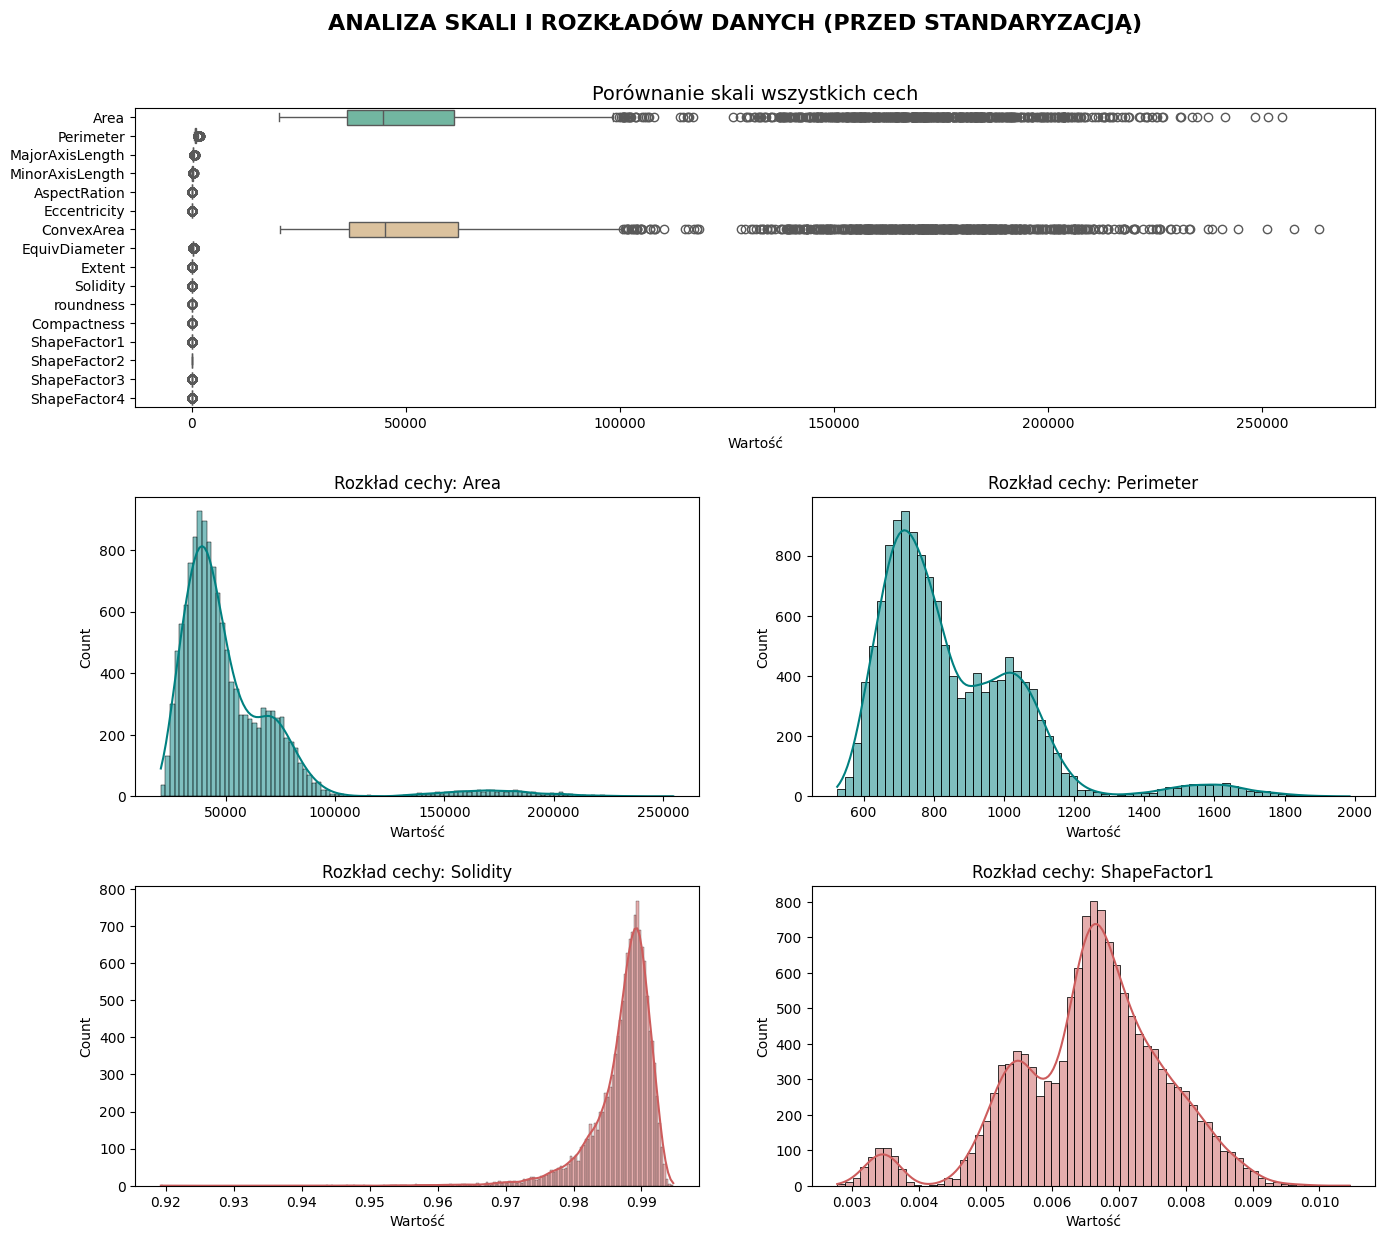


STATYSTYKI OPISOWE (Potwierdzenie różnic w skali):


,Area,Perimeter,Solidity,ShapeFactor1
min,20420.000000,524.736000,0.919246,0.002778
max,254616.000000,1985.370000,0.994677,0.010451
mean,53048.284549,855.283459,0.987143,0.006564
std,29324.095717,214.289696,0.004660,0.001128


In [30]:
fig = plt.figure(figsize=(16, 14))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.2)

# BOXPLOT
ax1 = fig.add_subplot(gs[0, :])
sns.boxplot(data=X, ax=ax1, palette="Set2", orient="h")
ax1.set_title("Porównanie skali wszystkich cech", fontsize=14)
ax1.set_xlabel("Wartość")

# HISTOGRAMY
features_to_plot = ['Area', 'Perimeter', 'Solidity', 'ShapeFactor1']
colors = ['teal', 'teal', 'indianred', 'indianred']

for i, col in enumerate(features_to_plot):
    # Dynamiczne wybieranie miejsca w siatce (rzędy 1-2, kolumny 0-1)
    ax = fig.add_subplot(gs[(i // 2) + 1, i % 2])
    sns.histplot(X[col], kde=True, ax=ax, color=colors[i])
    ax.set_title(f'Rozkład cechy: {col}')
    ax.set_xlabel("Wartość")

fig.suptitle('ANALIZA SKALI I ROZKŁADÓW DANYCH (PRZED STANDARYZACJĄ)', fontsize=16, fontweight='bold', y=0.95)
plt.show()

# STATYSTYKI (Pod wykresami)
print("\n" + "="*50)
print("STATYSTYKI OPISOWE (Potwierdzenie różnic w skali):")
print("="*50)
display(X[features_to_plot].describe().loc[['min', 'max', 'mean', 'std']])

* Cecha **Area** osiąga wartości rzędu **250 000**, podczas gdy **ShapeFactor1** oscyluje w granicach **0.003 - 0.009.** Bez standaryzacji model brałby pod uwagę tylko zmiany w polu powierzchni, całkowicie ignorując subtelne, ale kluczowe różnice w kształcie fasoli.

* Wykresy pudełkowe oraz **długie ogony** w histogramach (np. dla Area i Perimeter) wskazują na obecność ziarn o **nietypowych rozmiarach.** Standaryzacja (StandardScaler) pomoże zneutralizować wpływ tych wartości na wagi sieci, przesuwając środek ciężkości danych do zera.






# 4. Budowa funkcji

## 4.1 Funkcja TRENINGU

In [5]:
def train_model(model, name, train_loader, val_loader, opt_type='adam', epochs=100, lr=0.001, wd=0.0):
    criterion = nn.CrossEntropyLoss()

    if opt_type == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr)

    history = {'t_loss': [], 'v_loss': [], 't_acc': [],'v_acc': []}
    best_v_loss = float('inf')
    patience = 7
    counter = 0

    print(f'\n>>> Rozpoczęto trening modelu: {name}')

    for epoch in range(epochs):
        # FAZA TRENINGU
        model.train()
        t_loss = 0.0
        t_correct = 0

        for inputs, targets in train_loader:
            optimizer.zero_grad()
            out = model(inputs)
            loss = criterion(out, targets)
            loss.backward()
            optimizer.step()
            t_loss += loss.item()
            t_correct += (out.argmax(1) == targets).sum().item()

        # FAZA WALIDACJI
        model.eval()
        v_loss, correct = 0.0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                out = model(inputs)
                v_loss += criterion(out, targets).item()
                correct += (out.argmax(1) == targets).sum().item()

        # Obliczanie średnich
        avg_t = t_loss / len(train_loader)
        avg_v = v_loss / len(val_loader)

        # Obliczanie dokładności dla obu zbiorów
        avg_t_acc = t_correct / len(train_loader.dataset)
        acc = correct / len(val_loader.dataset)

        # Zapis do historii
        history['t_loss'].append(avg_t)
        history['v_loss'].append(avg_v)
        history['t_acc'].append(avg_t_acc)
        history['v_acc'].append(acc)

        # Logowanie co 5 epok
        if (epoch + 1) % 5 == 0:
            print(f'Epoka {epoch+1:2d} | Train Loss: {avg_t:.4f} | Val Loss: {avg_v:.4f} | Train Acc: {avg_t_acc:.4f} | Val Acc: {acc:.4f}')

        # Early Stopping i zapis najlepszego modelu
        if avg_v < best_v_loss:
            best_v_loss = avg_v
            counter = 0
            # Zapisujemy stan wag najlepszego momentu
            torch.save(model.state_dict(), f'best_model_{name}.pth')
        else:
            counter += 1
            if counter >= patience:
                print(f'--- Early Stopping w epoce {epoch+1} ---')
                break

    return history

## 4.1.2 Funkcja TRENINGU (bez early stopping)

In [6]:
def train_model_no_early_stopping(
    model,
    name,
    train_loader,
    val_loader,
    opt_type="adam",
    epochs=100,
    lr=0.001,
    wd=0.0,
):
    criterion = nn.CrossEntropyLoss()

    if opt_type == "adam":
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=wd)

    history = {
        "t_loss": [],
        "v_loss": [],
        "t_acc": [],
        "v_acc": [],
    }

    print(f"\n>>> Rozpoczęto trening modelu: {name}")

    for epoch in range(epochs):
        model.train()
        t_loss = 0.0
        t_correct = 0

        for inputs, targets in train_loader:
            optimizer.zero_grad()
            out = model(inputs)
            loss = criterion(out, targets)
            loss.backward()
            optimizer.step()

            t_loss += loss.item()
            t_correct += (out.argmax(1) == targets).sum().item()

        model.eval()
        v_loss = 0.0
        correct = 0

        with torch.no_grad():
            for inputs, targets in val_loader:
                out = model(inputs)
                v_loss += criterion(out, targets).item()
                correct += (out.argmax(1) == targets).sum().item()

        avg_t = t_loss / len(train_loader)
        avg_v = v_loss / len(val_loader)
        avg_t_acc = t_correct / len(train_loader.dataset)
        avg_v_acc = correct / len(val_loader.dataset)

        history["t_loss"].append(avg_t)
        history["v_loss"].append(avg_v)
        history["t_acc"].append(avg_t_acc)
        history["v_acc"].append(avg_v_acc)

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoka {epoch+1:2d} | Train Loss: {avg_t:.4f} | Val Loss: {avg_v:.4f} | "
                f"Train Acc: {avg_t_acc:.4f} | Val Acc: {avg_v_acc:.4f}"
            )

    torch.save(model.state_dict(), f"best_model_{name}_noES.pth")

    return history

## 4.2 Funkcja WYKRESU

In [7]:
def plot_training_results(history, name):
    epochs = range(1, len(history['t_loss']) + 1)

    plt.figure(figsize=(12, 5))

    # Wykres Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['t_loss'], 'b-', label='Strata treningu')
    plt.plot(epochs, history['v_loss'], 'r-', label='Strata walidacji')
    plt.title(f'Funkcja straty - {name}')
    plt.xlabel('Epoki')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Wykres Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['t_acc'], 'y-', label='Dokładność treningu')
    plt.plot(epochs, history['v_acc'], 'g-', label='Dokładność walidacji')
    plt.title(f'Dokładność (Accuracy) - {name}')
    plt.xlabel('Epoki')
    plt.ylabel('Acc')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

## 4.3 Funkcja PORÓWNAWCZA

In [8]:
def compare_models(histories, names):

    # histories: lista słowników history zwróconych przez train_model
    # names: lista nazw modeli do wyświetlenia w legendzie

    plt.figure(figsize=(14, 6))

    # Wykres błędu walidacyjnego (Val Loss)
    plt.subplot(1, 2, 1)
    for hist, name in zip(histories, names):
        plt.plot(hist['v_loss'], label=f'{name} (Loss)')
    plt.title('Porównanie błędu walidacji (Val Loss)')
    plt.xlabel('Epoki')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Wykres dokładności walidacyjnej (Val Accuracy)
    plt.subplot(1, 2, 2)
    for hist, name in zip(histories, names):
        plt.plot(hist['v_acc'], label=f'{name} (Acc)')
    plt.title('Porównanie dokładności walidacji (Val Acc)')
    plt.xlabel('Epoki')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# 5. Budowa modeli

## Model 1: Mała sieć 12 neuronów, ReLU, SGD
Mała sieć neuronowa z jedną warstwą ukrytą zawierającą **12 neuronów** i funkcją aktywacji **ReLU**, która przy użyciu **optymalizatora SGD** służy jako prosty punkt odniesienia do badania wydajności bardziej złożonych struktur.


>>> Rozpoczęto trening modelu: 1_Small_12_ReLU_SGD
Epoka  5 | Train Loss: 1.7473 | Val Loss: 1.7198 | Train Acc: 0.4179 | Val Acc: 0.4314
Epoka 10 | Train Loss: 1.5179 | Val Loss: 1.4974 | Train Acc: 0.4785 | Val Acc: 0.4833
Epoka 15 | Train Loss: 1.3482 | Val Loss: 1.3321 | Train Acc: 0.5073 | Val Acc: 0.5162
Epoka 20 | Train Loss: 1.2218 | Val Loss: 1.2085 | Train Acc: 0.5203 | Val Acc: 0.5304
Epoka 25 | Train Loss: 1.1205 | Val Loss: 1.1083 | Train Acc: 0.5350 | Val Acc: 0.5436
Epoka 30 | Train Loss: 1.0315 | Val Loss: 1.0201 | Train Acc: 0.5558 | Val Acc: 0.5593
Epoka 35 | Train Loss: 0.9494 | Val Loss: 0.9383 | Train Acc: 0.6106 | Val Acc: 0.6175
Epoka 40 | Train Loss: 0.8723 | Val Loss: 0.8622 | Train Acc: 0.7053 | Val Acc: 0.7091
Epoka 45 | Train Loss: 0.8031 | Val Loss: 0.7939 | Train Acc: 0.7403 | Val Acc: 0.7424
Epoka 50 | Train Loss: 0.7436 | Val Loss: 0.7356 | Train Acc: 0.7660 | Val Acc: 0.7625
Epoka 55 | Train Loss: 0.6940 | Val Loss: 0.6870 | Train Acc: 0.7873 | Val Acc

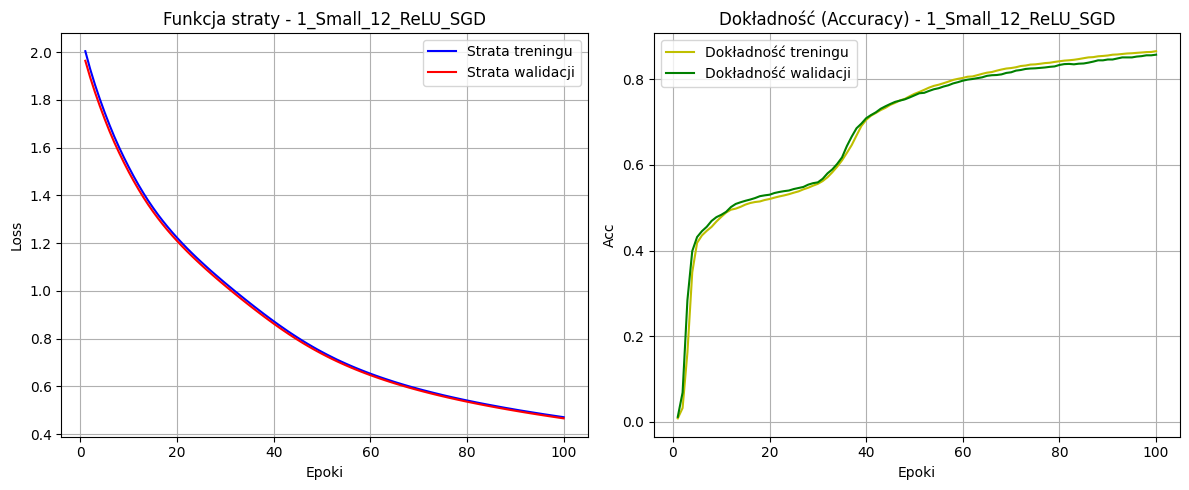

In [9]:
class M1(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 12)
        self.fc2 = nn.Linear(12, 7)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

m1_model = M1()
m1_name  = "1_Small_12_ReLU_SGD"

m1_history = train_model(m1_model, m1_name, train_loader, val_loader, opt_type="sgd", epochs=100, lr=0.001, wd=0.0)

plot_training_results(m1_history, m1_name)

## Model 2: Mała sieć 12 neuronów, ReLU, Adam
Konstrukcja identyczna jak w przypadku modelu pierwszego, wykorzystująca **12 neuronów** i funkcję **ReLU**, jednak zastąpienie klasycznego SGD **optymalizatorem Adam** pozwala sprawdzić wpływ adaptacyjnego tempa uczenia na szybkość zbieżności małej sieci.


>>> Rozpoczęto trening modelu: 2_Small_12_ReLU_Adam
Epoka  5 | Train Loss: 0.3907 | Val Loss: 0.3604 | Train Acc: 0.8765 | Val Acc: 0.8913
Epoka 10 | Train Loss: 0.2425 | Val Loss: 0.2329 | Train Acc: 0.9187 | Val Acc: 0.9207
Epoka 15 | Train Loss: 0.2148 | Val Loss: 0.2115 | Train Acc: 0.9246 | Val Acc: 0.9221
Epoka 20 | Train Loss: 0.2046 | Val Loss: 0.2067 | Train Acc: 0.9282 | Val Acc: 0.9241
Epoka 25 | Train Loss: 0.1987 | Val Loss: 0.2034 | Train Acc: 0.9278 | Val Acc: 0.9236
Epoka 30 | Train Loss: 0.1945 | Val Loss: 0.2027 | Train Acc: 0.9295 | Val Acc: 0.9256
Epoka 35 | Train Loss: 0.1916 | Val Loss: 0.2008 | Train Acc: 0.9301 | Val Acc: 0.9261
Epoka 40 | Train Loss: 0.1902 | Val Loss: 0.2013 | Train Acc: 0.9304 | Val Acc: 0.9275
--- Early Stopping w epoce 42 ---


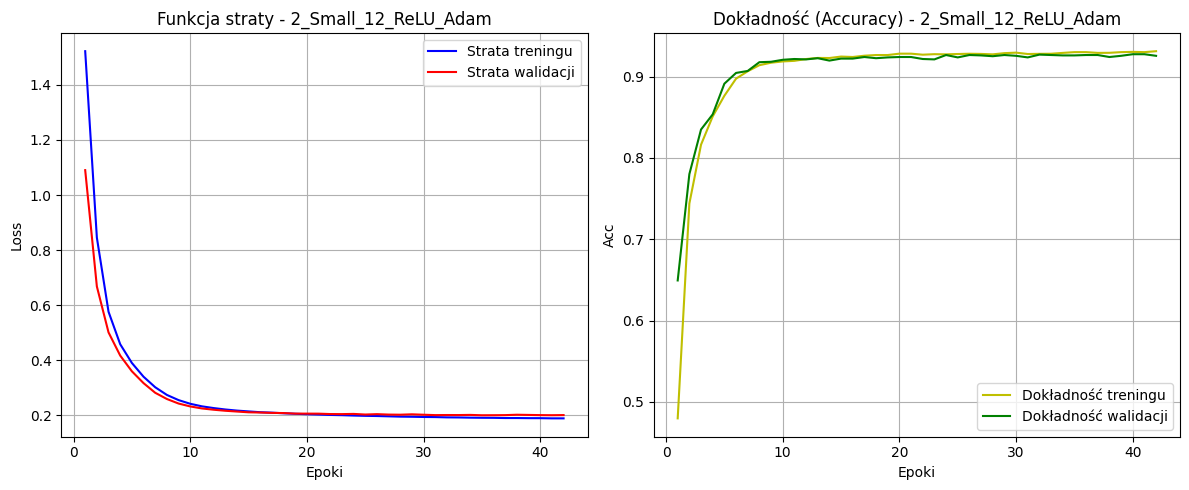

In [33]:
class M1(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 12)
        self.fc2 = nn.Linear(12, 7)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

m2_model = M1()
m2_name  = "2_Small_12_ReLU_Adam"

m2_history = train_model(m2_model, m2_name, train_loader, val_loader, opt_type="adam", epochs=100, lr=0.001, wd=0.0)

plot_training_results(m2_history, m2_name)

## Porównanie modeli 1 i 2: Wpływ wyboru optymalizatora na proces uczenia

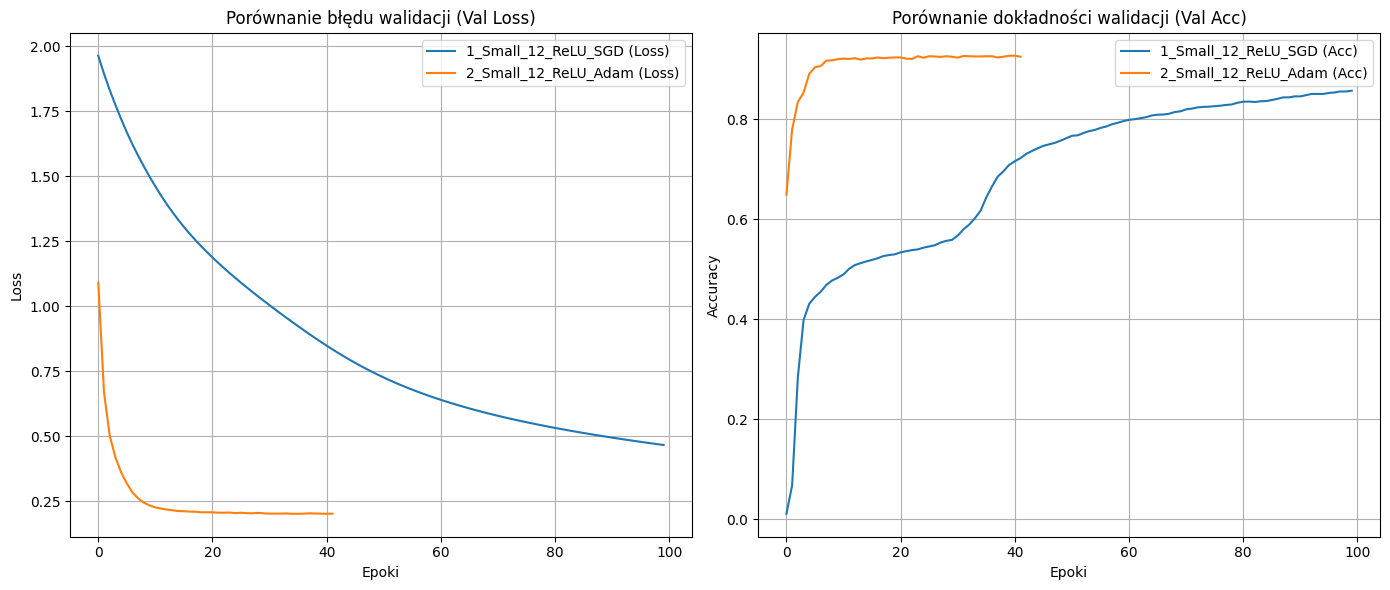

In [37]:
compare_models(
    histories=[m1_history, m2_history],
    names=[m1_name, m2_name]
)

**Wnioski**

Bezpośrednie zestawienie modelu opartego na klasycznym algorytmie **SGD (Model 1)** z wariantem wykorzystującym optymalizator **Adam (Model 2)** przy zachowaniu identycznej architektury sieci pozwala ocenić wpływ dynamiki uczenia na końcowe wyniki.

Zastosowanie **optymalizatora Adam** umożliwiło **znacznie szybszą** stabilizację procesu treningowego oraz uzyskanie niższych wartości funkcji straty już w początkowych epokach, co potwierdza przewagę algorytmów z **adaptacyjnym** tempem uczenia w zadaniu klasyfikacji.

### Eksperyment 1: Wpływ standaryzacji na proces uczenia
W tym kroku porównujemy wydajność najlepszej małej architektury (12 neuronów) trenowanej na danych surowych z wynikami uzyskanymi po zastosowaniu standaryzacji (StandardScaler). Celem jest sprawdzenie, w jakim stopniu ogromne różnice w skalach cech geometrycznych fasoli ograniczają zdolność sieci do znalezienia optymalnych wag.


>>> Rozpoczęto trening modelu: 2_Small_12_ReLU_Adam_NO_STD
Epoka  5 | Train Loss: 20.0487 | Val Loss: 16.9179 | Train Acc: 0.2415 | Val Acc: 0.2791
Epoka 10 | Train Loss: 13.3320 | Val Loss: 12.4597 | Train Acc: 0.2961 | Val Acc: 0.2938
Epoka 15 | Train Loss: 10.5573 | Val Loss: 11.3175 | Train Acc: 0.3432 | Val Acc: 0.3404
Epoka 20 | Train Loss: 12.2059 | Val Loss: 29.8855 | Train Acc: 0.3551 | Val Acc: 0.2576
--- Early Stopping w epoce 23 ---


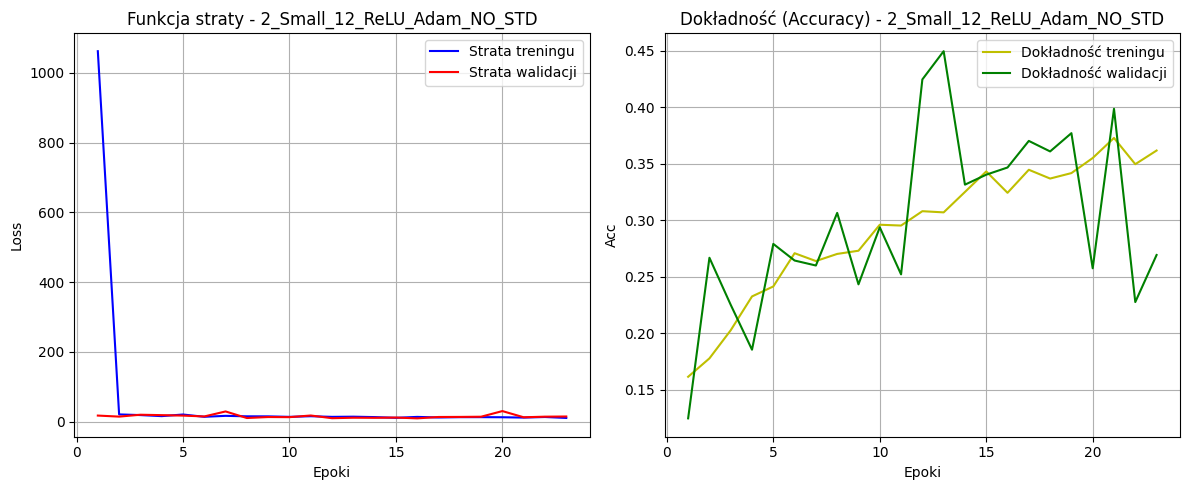

In [12]:
# Odniesienie do historii najlepszego modelu ze standaryzacją
best_std_history = m2_history
best_base_name   = m2_name
BestModelClass   = M1

# Trening na danych bez standaryzacji
best_raw_model = BestModelClass()
best_raw_name  = best_base_name + "_NO_STD"

best_raw_history = train_model(
    best_raw_model,
    best_raw_name,
    train_loader2,
    val_loader2,
    opt_type='adam',
    epochs=100,
    lr=0.001,
    wd=0.0,
)

plot_training_results(best_raw_history, best_raw_name)

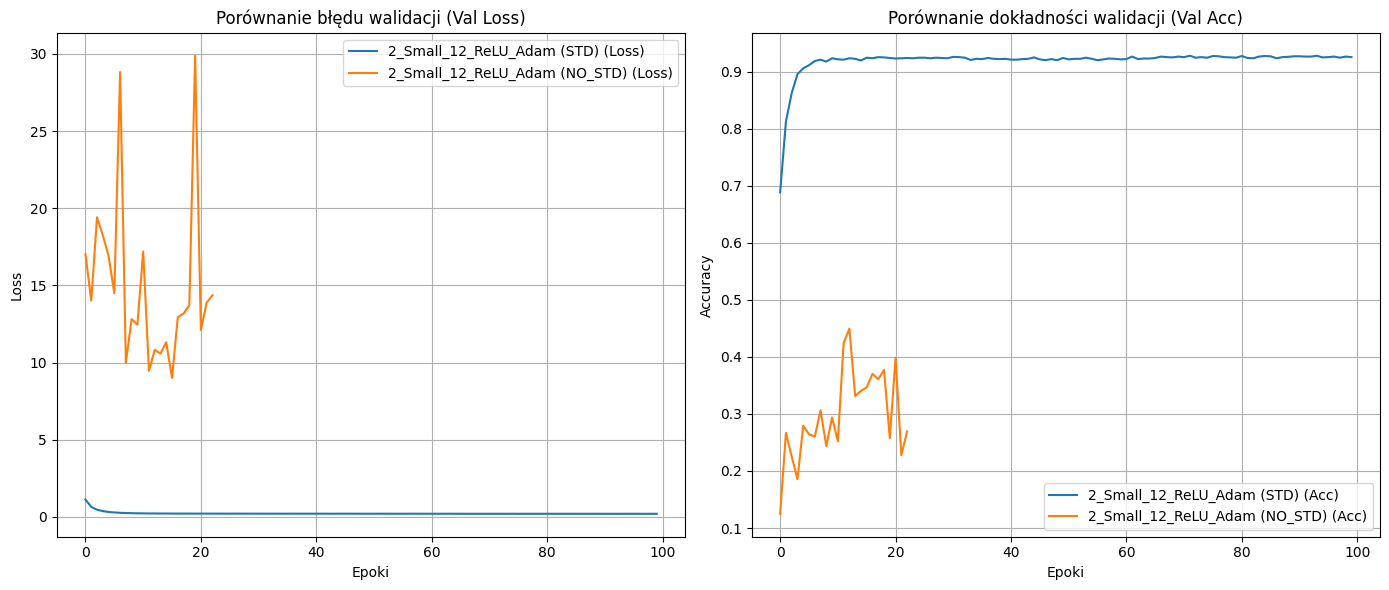

In [13]:
# Porównanie tych samych modeli wytrenowanych na danych ze standaryzacja vs bez standaryzacji
compare_models(
    histories=[best_std_history, best_raw_history],
    names=[
        best_base_name + " (STD)",
        best_base_name + " (NO_STD)",
    ]
)

**Wnioski**

Zestawienie modelu trenowanego na **surowych danych** z jego standaryzowanym odpowiednikiem wykazało, że brak wstępnego przetwarzania danych drastycznie utrudnia proces optymalizacji.

Model **bez standaryzacji** osiągnął znacznie **niższą precyzję** i wykazywał **niestabilność funkcji straty**, co jednoznacznie potwierdza, że sprowadzenie wszystkich cech do wspólnej skali jest kluczowym elementem poprawy skuteczności klasyfikacji w przypadku zbioru Dry Bean Dataset.

## Model 3: Średnia sieć 64 neurony, ReLU, Adam
Model o umiarkowanej złożoności z warstwą ukrytą liczącą **64 neurony**, wykorzystujący najpopularniejszą funkcję aktywacji **ReLU**, która dzięki swojej prostocie stanowi optymalny punkt wyjścia dla sieci o średniej wielkości.


>>> Rozpoczęto trening modelu: 3_Med_64_ReLU_Adam
Epoka  5 | Train Loss: 0.2222 | Val Loss: 0.2165 | Train Acc: 0.9221 | Val Acc: 0.9221
Epoka 10 | Train Loss: 0.1996 | Val Loss: 0.2011 | Train Acc: 0.9282 | Val Acc: 0.9290
Epoka 15 | Train Loss: 0.1907 | Val Loss: 0.1993 | Train Acc: 0.9300 | Val Acc: 0.9265
Epoka 20 | Train Loss: 0.1857 | Val Loss: 0.2002 | Train Acc: 0.9309 | Val Acc: 0.9246
Epoka 25 | Train Loss: 0.1827 | Val Loss: 0.1966 | Train Acc: 0.9324 | Val Acc: 0.9280
Epoka 30 | Train Loss: 0.1791 | Val Loss: 0.1946 | Train Acc: 0.9349 | Val Acc: 0.9310
--- Early Stopping w epoce 34 ---


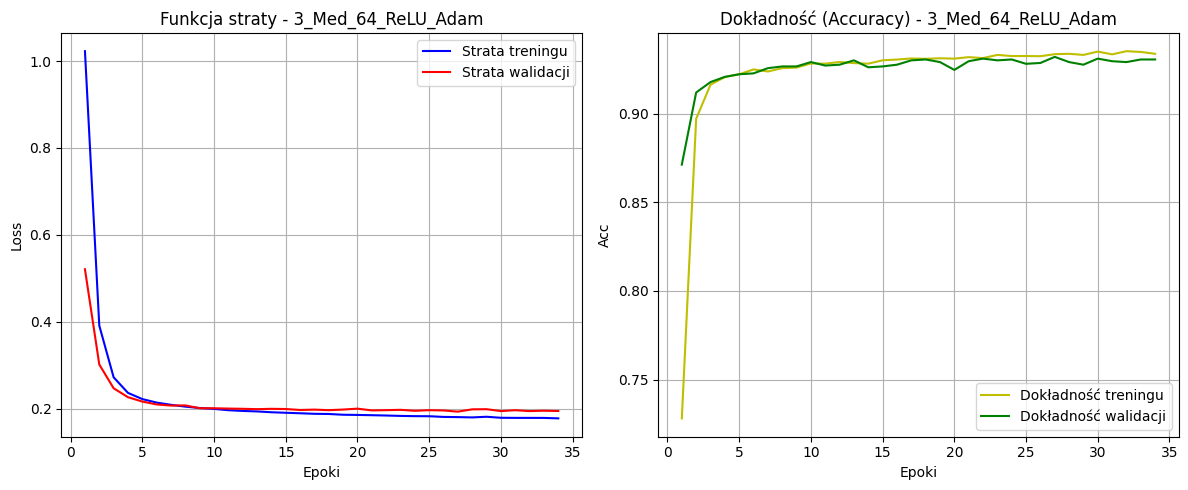

In [14]:
class M3(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 64)
        self.fc2 = nn.Linear(64, 7)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

m3_model = M3()
m3_name  = "3_Med_64_ReLU_Adam"

m3_history = train_model(m3_model, m3_name, train_loader, val_loader, opt_type="adam", epochs=100, lr=0.001, wd=0.0)

plot_training_results(m3_history, m3_name)

## Model 4: Średnia sieć 64 neurony, Sigmoid, Adam
Wariant wykorzystujący klasyczną funkcję **sigmoidalną**, która mapuje sygnały do przedziału **(0, 1)**.


>>> Rozpoczęto trening modelu: 4_Med_64_Sigmoid_Adam
Epoka  5 | Train Loss: 0.3611 | Val Loss: 0.3312 | Train Acc: 0.9117 | Val Acc: 0.9123
Epoka 10 | Train Loss: 0.2515 | Val Loss: 0.2452 | Train Acc: 0.9196 | Val Acc: 0.9153
Epoka 15 | Train Loss: 0.2287 | Val Loss: 0.2241 | Train Acc: 0.9222 | Val Acc: 0.9182
Epoka 20 | Train Loss: 0.2176 | Val Loss: 0.2161 | Train Acc: 0.9240 | Val Acc: 0.9182
Epoka 25 | Train Loss: 0.2110 | Val Loss: 0.2101 | Train Acc: 0.9250 | Val Acc: 0.9226
Epoka 30 | Train Loss: 0.2059 | Val Loss: 0.2064 | Train Acc: 0.9262 | Val Acc: 0.9231
Epoka 35 | Train Loss: 0.2015 | Val Loss: 0.2028 | Train Acc: 0.9272 | Val Acc: 0.9226
Epoka 40 | Train Loss: 0.1980 | Val Loss: 0.2003 | Train Acc: 0.9282 | Val Acc: 0.9236
Epoka 45 | Train Loss: 0.1957 | Val Loss: 0.2002 | Train Acc: 0.9295 | Val Acc: 0.9246
Epoka 50 | Train Loss: 0.1936 | Val Loss: 0.1977 | Train Acc: 0.9275 | Val Acc: 0.9270
Epoka 55 | Train Loss: 0.1910 | Val Loss: 0.1988 | Train Acc: 0.9303 | Val A

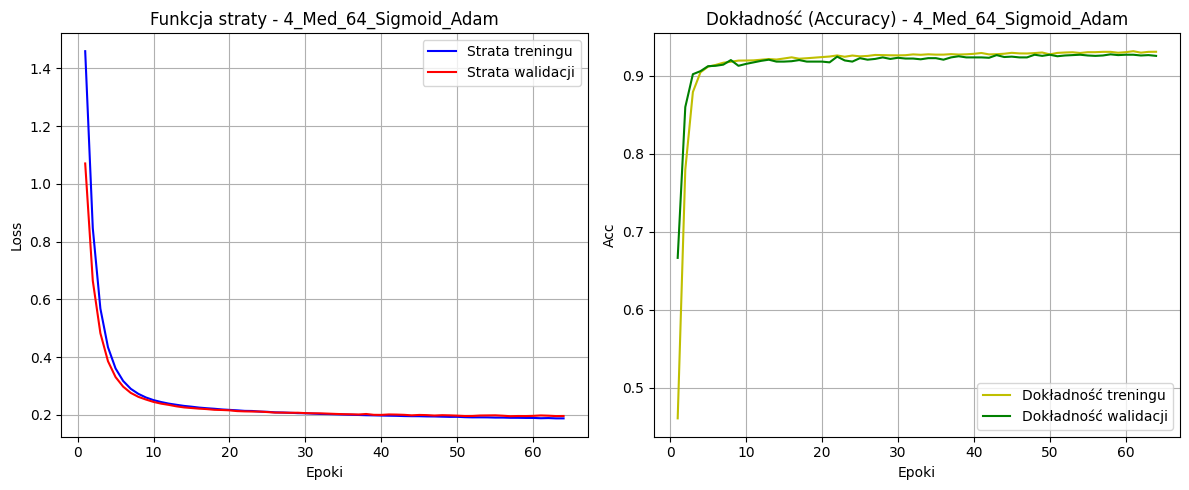

In [41]:
class M4(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 64)
        self.fc2 = nn.Linear(64, 7)

    def forward(self, x):
        x = torch.sigmoid(self.fc1(x))
        x = self.fc2(x)
        return x

m4_model = M4()
m4_name  = "4_Med_64_Sigmoid_Adam"

m4_history = train_model(m4_model, m4_name, train_loader, val_loader, opt_type="adam", epochs=100, lr=0.001, wd=0.0)

plot_training_results(m4_history, m4_name)

## Model 5: Średnia sieć 64 neurony, Tanh, Adam
Model oparty na **tangesie hiperbolicznym**, który dzięki centrowaniu danych wokół zera w przedziale **(-1, 1)** często oferuje szybszą zbieżność niż funkcja Sigmoid, stanowiąc klasyczną alternatywę dla nieliniowości ReLU.


>>> Rozpoczęto trening modelu: 5_Med_64_Tanh_Adam
Epoka  5 | Train Loss: 0.2264 | Val Loss: 0.2193 | Train Acc: 0.9231 | Val Acc: 0.9216
Epoka 10 | Train Loss: 0.2052 | Val Loss: 0.2021 | Train Acc: 0.9258 | Val Acc: 0.9241
Epoka 15 | Train Loss: 0.1974 | Val Loss: 0.1976 | Train Acc: 0.9287 | Val Acc: 0.9270
Epoka 20 | Train Loss: 0.1926 | Val Loss: 0.1942 | Train Acc: 0.9298 | Val Acc: 0.9300
Epoka 25 | Train Loss: 0.1892 | Val Loss: 0.1977 | Train Acc: 0.9307 | Val Acc: 0.9256
--- Early Stopping w epoce 28 ---


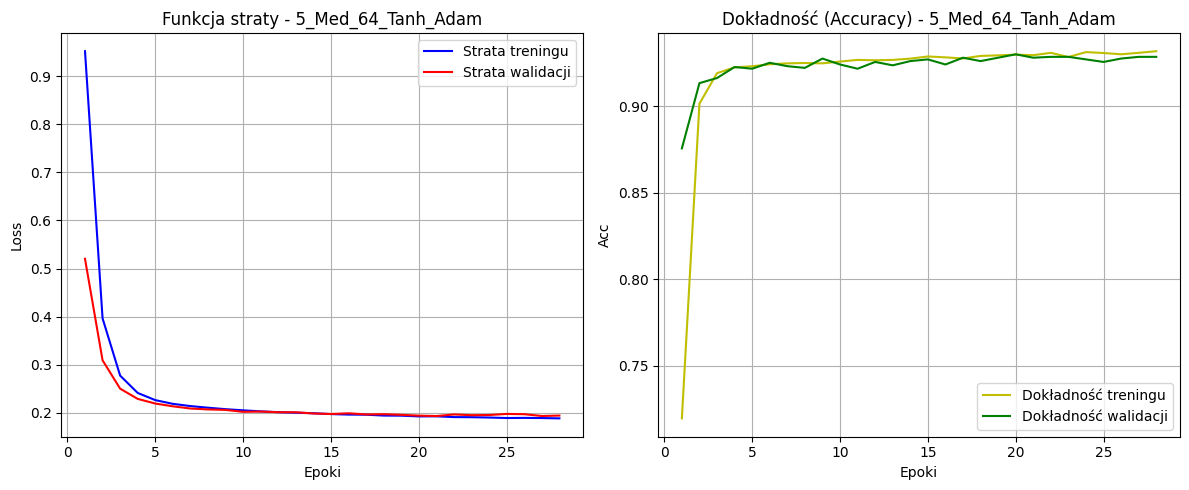

In [16]:
class M5(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 64)
        self.fc2 = nn.Linear(64, 7)

    def forward(self, x):
        x = torch.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

m5_model = M5()
m5_name  = "5_Med_64_Tanh_Adam"

m5_history = train_model(m5_model, m5_name, train_loader, val_loader, opt_type="adam", epochs=100, lr=0.001, wd=0.0)

plot_training_results(m5_history, m5_name)

## Porównanie modeli 3, 4 i 5: Wpływ funkcji aktywacji
W tej części projektu poddajemy testom trzy identyczne architektury (64 neurony w warstwie ukrytej, optymalizator Adam), w których jedyną zmienną jest zastosowana funkcja aktywacji. Porównujemy klasyczną funkcję **ReLU (Model 3)** z funkcjami sigmoidalnymi: **Sigmoid (Model 4)** oraz **Tanh (Model 5).** Celem jest sprawdzenie, jak matematyczna charakterystyka każdej z tych funkcji wpływa na szybkość zbieżności i zdolność sieci do klasyfikacji.

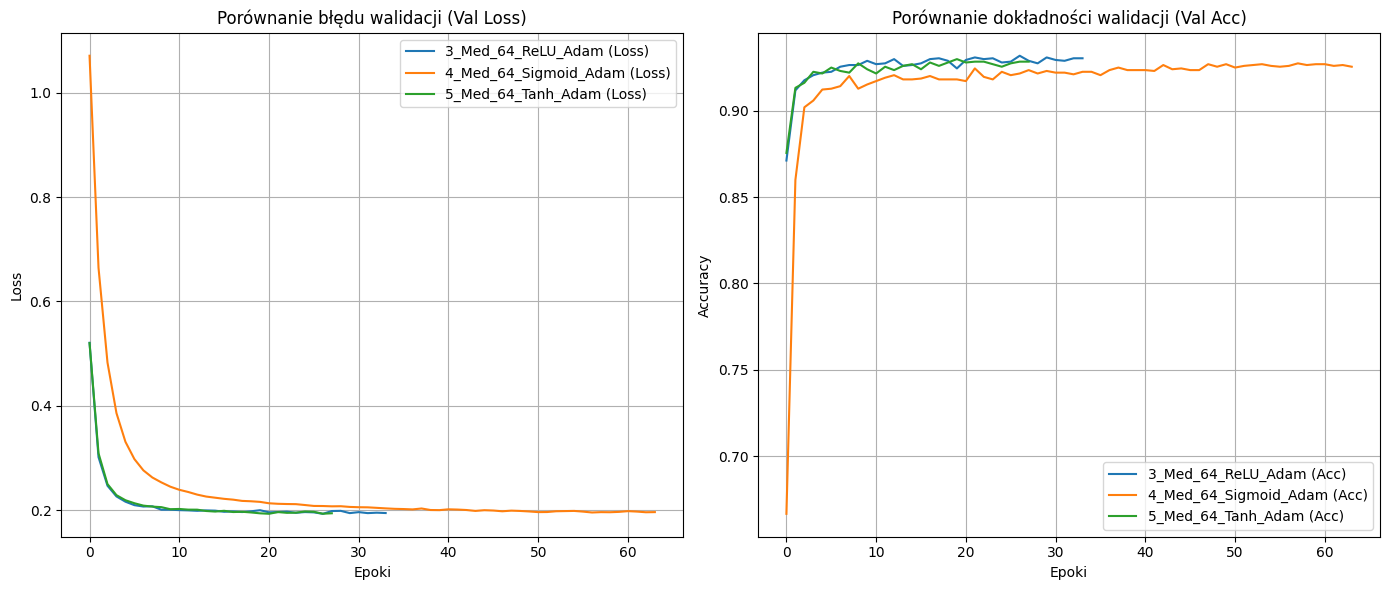

In [42]:
compare_models(
    histories=[m3_history, m4_history, m5_history],
    names=[m3_name, m4_name, m5_name]
)

**Wnioski**

* Porównanie trzech funkcji aktywacji wykazało wyraźną przewagę funkcji ReLU oraz Tanh nad klasyczną funkcją Sigmoid. Model wykorzystujący **Sigmoid** uzyskał najsłabsze wyniki. Z kolei **ReLU i Tanh osiągnęły bardzo zbliżone rezultaty**, przy czym **Tanh** wykazało nieznaczną przewagę pod kątem **dokładności** (accuracy) na zbiorze walidacyjnym.

* Ostatecznie, mimo że **ReLU jest standardem** w głębokim uczeniu ze względu na wydajność obliczeniową, w tym konkretnym zadaniu funkcja **Tanh** okazała się **najskuteczniejsza.** Wynika to prawdopodobnie z faktu, że Tanh **mapuje wartości** wejściowe do przedziału **$(-1, 1)$**, co w połączeniu ze **standaryzacją** danych wejściowych przyspiesza proces optymalizacji na danych o charakterze geometrycznym.

## Model 6: Duża sieć 256 neuronów, Tanh + Dropout, Adam
Model 6 to „szeroka” sieć z jedną dużą warstwą ukrytą (**256 neuronów**) oraz funkcją aktywacji **Tanh**.  
Dodajemy warstwę **Dropout**, aby ograniczyć przeuczenie przy takiej liczbie parametrów.  
Optymalizator: **Adam**, funkcja straty: **CrossEntropyLoss**, early stopping jak w pozostałych eksperymentach.


>>> Rozpoczęto trening modelu: 6_Big_256_Tanh_Adam_Dropout
Epoka  5 | Train Loss: 0.2294 | Val Loss: 0.2099 | Train Acc: 0.9175 | Val Acc: 0.9212
Epoka 10 | Train Loss: 0.2195 | Val Loss: 0.2031 | Train Acc: 0.9205 | Val Acc: 0.9216
Epoka 15 | Train Loss: 0.2169 | Val Loss: 0.1989 | Train Acc: 0.9233 | Val Acc: 0.9261
Epoka 20 | Train Loss: 0.2116 | Val Loss: 0.1958 | Train Acc: 0.9239 | Val Acc: 0.9285
Epoka 25 | Train Loss: 0.2096 | Val Loss: 0.1982 | Train Acc: 0.9246 | Val Acc: 0.9285
--- Early Stopping w epoce 27 ---


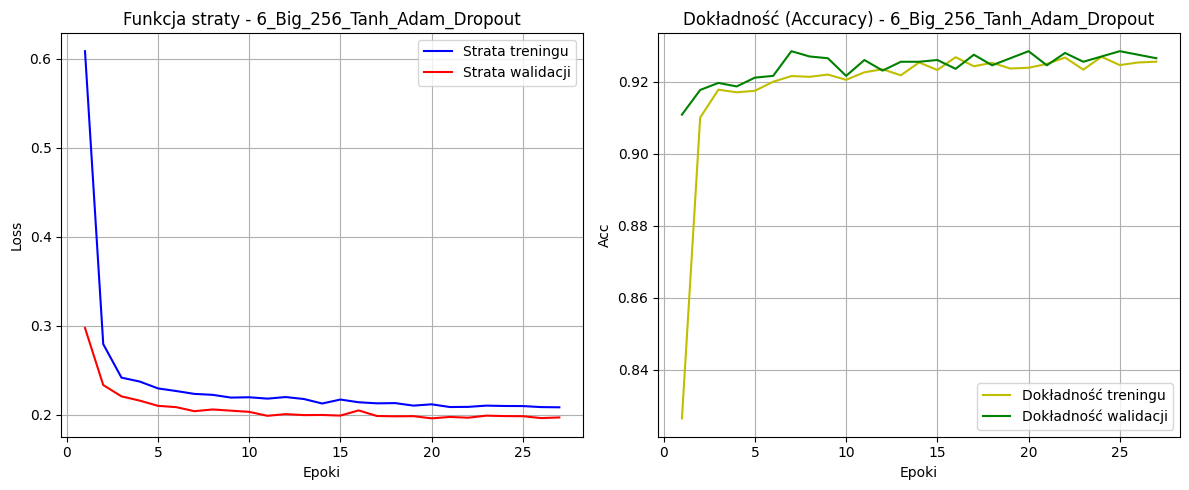

In [34]:
class M6(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 256)
        self.dropout = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(256, 7)

    def forward(self, x):
        x = torch.tanh(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

m6_model = M6()
m6_name  = "6_Big_256_Tanh_Adam_Dropout"

m6_history = train_model(m6_model, m6_name, train_loader, val_loader, opt_type="adam", epochs=100, lr=0.001, wd=0.0)

plot_training_results(m6_history, m6_name)

## Model 7: Głęboka sieć 2 warstwy (128–64), ReLU + L2 (weight decay), Adam
Model 7 to głębsza sieć z dwiema warstwami ukrytymi (**128 i 64 neurony**) oraz funkcją aktywacji **ReLU**.  
Do optymalizatora Adam dodajemy **L2 (weight decay)**, aby wprowadzić klasyczną regularyzację normy wag.  
Pozwala to porównać wpływ samego Dropoutu (Model 6) z regularyzacją L2 (Model 7).


>>> Rozpoczęto trening modelu: 7_Deep_128_64_ReLU_L2_Adam
Epoka  5 | Train Loss: 0.1984 | Val Loss: 0.2079 | Train Acc: 0.9290 | Val Acc: 0.9246
Epoka 10 | Train Loss: 0.1829 | Val Loss: 0.1944 | Train Acc: 0.9330 | Val Acc: 0.9275
Epoka 15 | Train Loss: 0.1804 | Val Loss: 0.1942 | Train Acc: 0.9343 | Val Acc: 0.9280
Epoka 20 | Train Loss: 0.1728 | Val Loss: 0.1974 | Train Acc: 0.9363 | Val Acc: 0.9256
Epoka 25 | Train Loss: 0.1703 | Val Loss: 0.1961 | Train Acc: 0.9349 | Val Acc: 0.9290
--- Early Stopping w epoce 25 ---


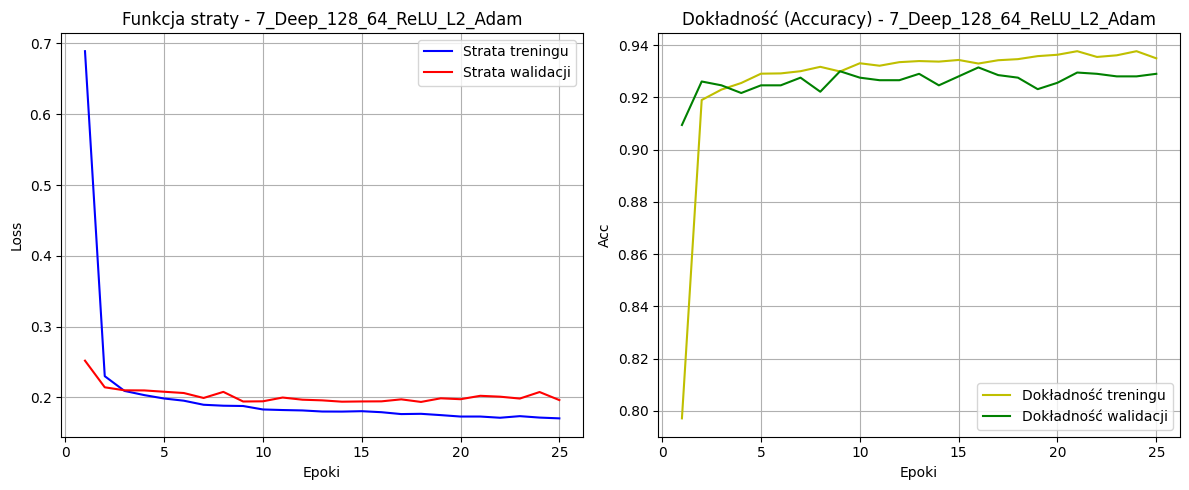

In [65]:
class M7(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 7)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

m7_model = M7()
m7_name  = "7_Deep_128_64_ReLU_L2_Adam"

m7_history = train_model(m7_model, m7_name, train_loader, val_loader, opt_type="adam", epochs=100, lr=0.001, wd=1e-4)

plot_training_results(m7_history, m7_name)

## Model 8: Głęboka sieć 3 warstwy (128–64–32), ReLU + 2x Dropout, Adam

Model 8 to najgłębsza rozważana architektura: trzy warstwy ukryte (**128–64–32** neurony) z aktywacją **ReLU**.  
Stosujemy **dwie warstwy Dropout** (po pierwszej i drugiej warstwie ukrytej), aby mocno ograniczyć przeuczenie.  
Optymalizator: Adam, funkcja straty: CrossEntropyLoss, early stopping jak w poprzednich eksperymentach.


>>> Rozpoczęto trening modelu: 8_Deep_128_64_32ReLU_Dropout_Adam
Epoka  5 | Train Loss: 0.3004 | Val Loss: 0.2171 | Train Acc: 0.9020 | Val Acc: 0.9221
Epoka 10 | Train Loss: 0.2676 | Val Loss: 0.2183 | Train Acc: 0.9115 | Val Acc: 0.9231
Epoka 15 | Train Loss: 0.2560 | Val Loss: 0.2108 | Train Acc: 0.9136 | Val Acc: 0.9241
Epoka 20 | Train Loss: 0.2425 | Val Loss: 0.2140 | Train Acc: 0.9178 | Val Acc: 0.9231
Epoka 25 | Train Loss: 0.2392 | Val Loss: 0.2125 | Train Acc: 0.9189 | Val Acc: 0.9256
Epoka 30 | Train Loss: 0.2348 | Val Loss: 0.2041 | Train Acc: 0.9190 | Val Acc: 0.9314
--- Early Stopping w epoce 33 ---


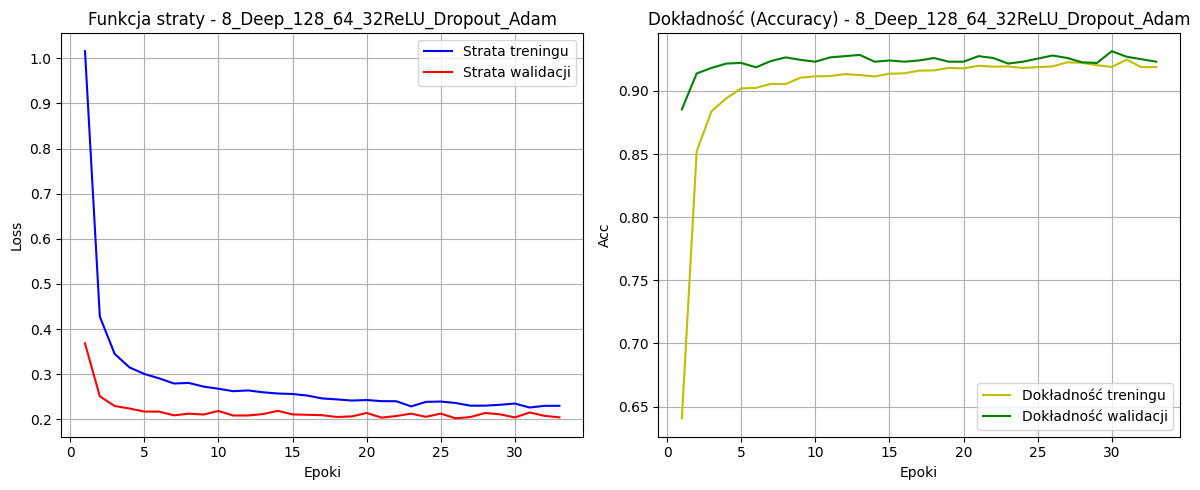

In [36]:
class M8(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(16, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 32)
        self.fc4 = nn.Linear(32, 7)

        self.dropout1 = nn.Dropout(p=0.5)
        self.dropout2 = nn.Dropout(p=0.5)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.dropout1(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout2(x)
        x = torch.relu(self.fc3(x))
        x = self.fc4(x)
        return x

m8_model = M8()
m8_name  = "8_Deep_128_64_32ReLU_Dropout_Adam"

m8_history = train_model(m8_model,m8_name,train_loader,val_loader,opt_type="adam",epochs=100,lr=0.001,wd=0.0)
plot_training_results(m8_history, m8_name)

## Porównanie modeli 6, 7 i 8 – wybór modelu bazowego do dalszych eksperymentów

Przed przejściem do eksperymentów 2 i 3 porównujemy trzy najbardziej zaawansowane architektury z projektu, czyli modele **6, 7 i 8**.  
Celem tej części jest wybranie jednego **najlepszego modelu bazowego**, który będzie następnie wykorzystany w dwóch eksperymentach.

Porównanie wykonujemy na podstawie przebiegów:

- **Val Loss** – aby ocenić jakość dopasowania modelu do danych walidacyjnych,
- **Val Accuracy** – aby sprawdzić skuteczność klasyfikacji,
- stabilności przebiegu uczenia – aby wykryć ewentualne oznaki przeuczenia lub niestabilnej optymalizacji.

Za najlepszy model przyjmujemy taki, który:

1. osiąga najwyższą lub bardzo wysoką **dokładność walidacyjną**,
2. utrzymuje niski i możliwie stabilny **błąd walidacyjny**,
3. nie wykazuje wyraźnych objawów przeuczenia,
4. daje najlepszy kompromis między skutecznością a generalizacją.

Wybrany model potraktujemy jako **model referencyjny**, który następnie porównamy:
- z tą samą architekturą trenowaną **bez standaryzacji** (eksperyment 2),
- oraz z tą samą architekturą trenowaną **bez regularyzacji i bez early stoppingu** (eksperyment 3).

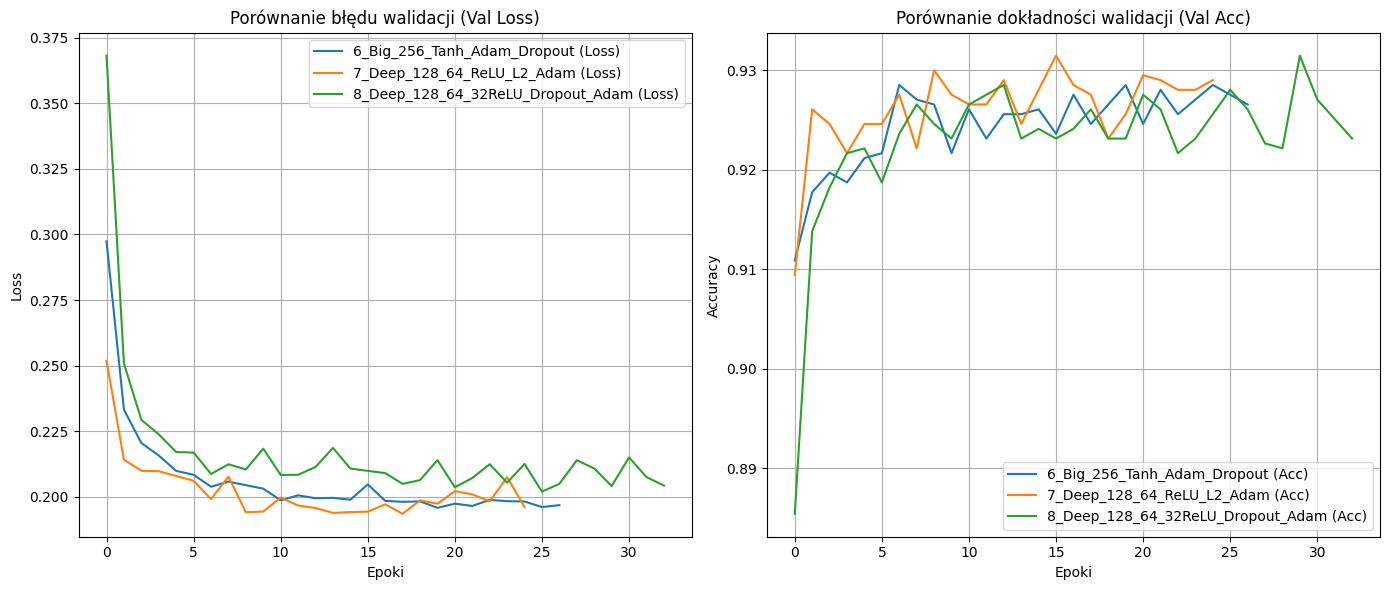

Najlepsze wartości Val Accuracy dla modeli 6, 7, 8:

6_Big_256_Tanh_Adam_Dropout: 0.9285
7_Deep_128_64_ReLU_L2_Adam: 0.9314
8_Deep_128_64_32ReLU_Dropout_Adam: 0.9314

Wybrany model bazowy do dalszych eksperymentów: 7_Deep_128_64_ReLU_L2_Adam


In [67]:
# Porównanie modeli 6, 7 i 8 na wspólnych wykresach
compare_models(
    histories=[m6_history, m7_history, m8_history],
    names=[m6_name, m7_name, m8_name]
)

# Dodatkowe zestawienie maksymalnego Val Accuracy
candidate_models = {
    m6_name: m6_history,
    m7_name: m7_history,
    m8_name: m8_history,
}

print("Najlepsze wartości Val Accuracy dla modeli 6, 7, 8:\n")
for name, hist in candidate_models.items():
    print(f"{name}: {max(hist['v_acc']):.4f}")

# Automatyczny wybór najlepszego modelu na podstawie maksymalnego Val Accuracy
best_model_name = max(candidate_models.keys(), key=lambda name: max(candidate_models[name]['v_acc']))
best_std_history = candidate_models[best_model_name]

print("\nWybrany model bazowy do dalszych eksperymentów:", best_model_name)

# Automatyczne przypisanie klasy najlepszego modelu
if best_model_name == m6_name:
    BestModelClass = M6
elif best_model_name == m7_name:
    BestModelClass = M7
elif best_model_name == m8_name:
    BestModelClass = M8

best_base_name = best_model_name

### Eksperyment 2: Najlepszy model na danych bez standaryzacji

W tym eksperymencie bierzemy najlepszą znalezioną architekturę (wytrenowaną wcześniej na danych **ze standaryzacją**) i trenujemy ją ponownie, ale na danych **bez standaryzacji** (`train_loader2`, `val_loader2`).  
Celem jest ponowne sprawdzenie, jak brak skalowania cech wpływa na zbieżność oraz dokładność walidacyjną tego samego modelu, natomiast znacznie bardziej rozbudowanego modelu niż ten w eksperymencie 1.


>>> Rozpoczęto trening modelu: 7_Deep_128_64_ReLU_L2_Adam_NO_STD
Epoka  5 | Train Loss: 85.8245 | Val Loss: 111.2225 | Train Acc: 0.1866 | Val Acc: 0.0480
Epoka 10 | Train Loss: 38.7086 | Val Loss: 30.6959 | Train Acc: 0.2689 | Val Acc: 0.0975
Epoka 15 | Train Loss: 19.2491 | Val Loss: 17.1847 | Train Acc: 0.3539 | Val Acc: 0.3619
Epoka 20 | Train Loss: 9.6277 | Val Loss: 7.7231 | Train Acc: 0.4201 | Val Acc: 0.3271
Epoka 25 | Train Loss: 7.5748 | Val Loss: 7.9091 | Train Acc: 0.4599 | Val Acc: 0.3482
Epoka 30 | Train Loss: 4.4863 | Val Loss: 4.4230 | Train Acc: 0.5005 | Val Acc: 0.4417
Epoka 35 | Train Loss: 2.4104 | Val Loss: 1.6955 | Train Acc: 0.3758 | Val Acc: 0.2620
Epoka 40 | Train Loss: 1.5740 | Val Loss: 1.6209 | Train Acc: 0.3908 | Val Acc: 0.3932
Epoka 45 | Train Loss: 1.5493 | Val Loss: 1.5360 | Train Acc: 0.3830 | Val Acc: 0.3565
Epoka 50 | Train Loss: 1.8466 | Val Loss: 1.8437 | Train Acc: 0.1937 | Val Acc: 0.1939
--- Early Stopping w epoce 51 ---


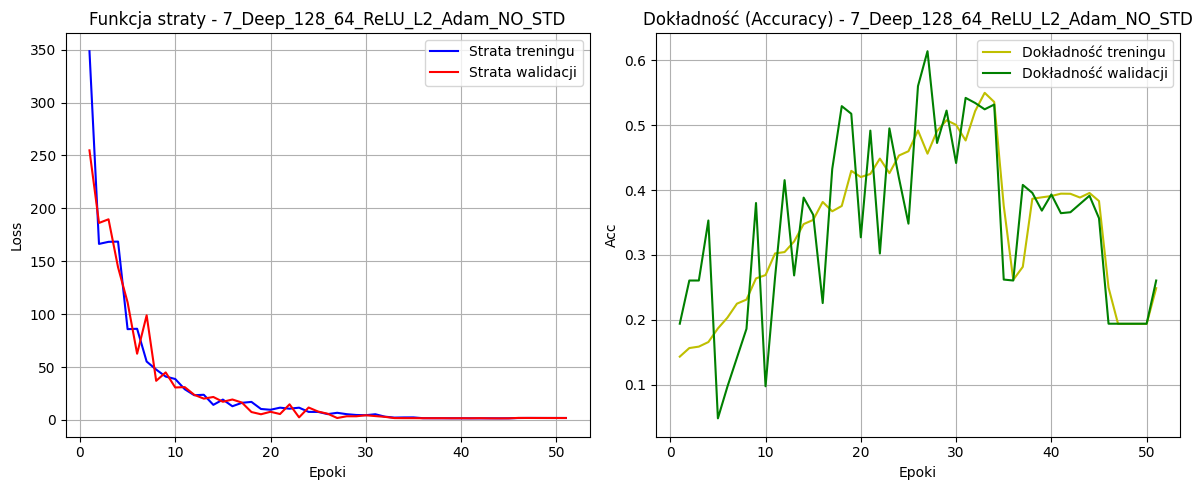

In [68]:
# Odniesienie do historii najlepszego modelu ze standaryzacją (model numer 7)
best_std_history = m7_history
best_base_name   = m7_name
BestModelClass   = M7

# Trening na danych bez standaryzacji
best_raw_model = BestModelClass()
best_raw_name  = best_base_name + "_NO_STD"

best_raw_history = train_model(
    best_raw_model,
    best_raw_name,
    train_loader2,
    val_loader2,
    opt_type='adam',
    epochs=100,
    lr=0.001,
    wd=0.0,
)

plot_training_results(best_raw_history, best_raw_name)

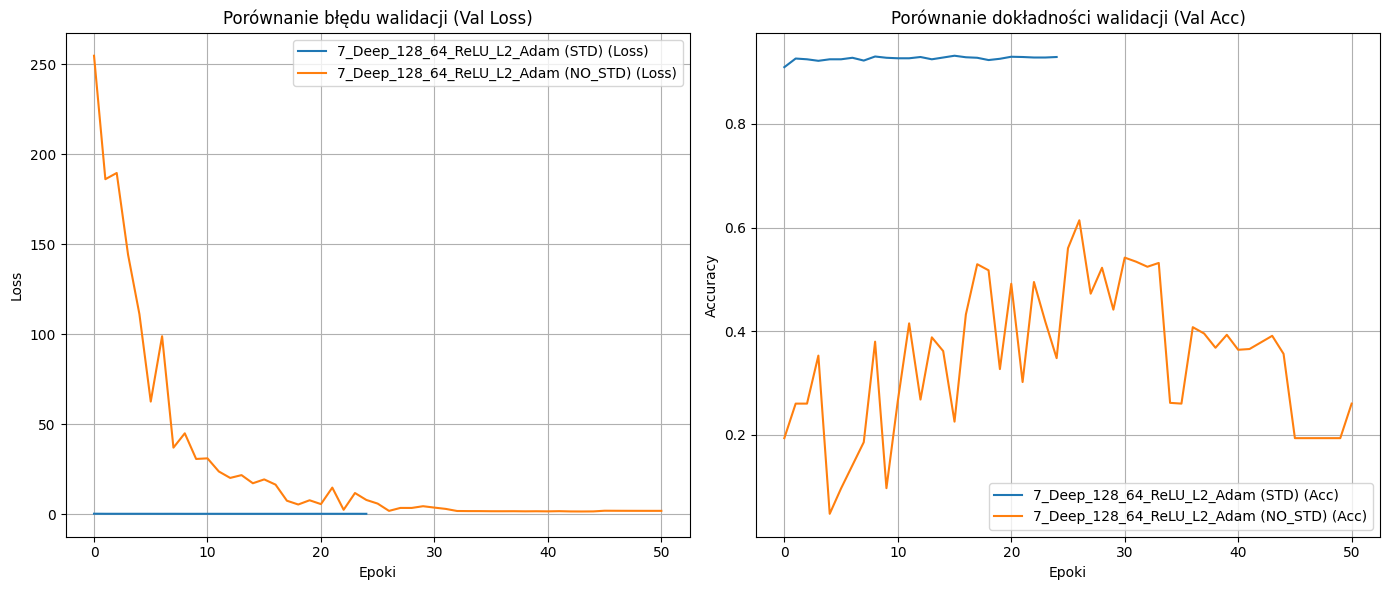

In [69]:
# Porównanie tych samych modeli wytrenowanych na danych ze standaryzacja vs bez standaryzacji
compare_models(
    histories=[best_std_history, best_raw_history],
    names=[
        best_base_name + " (STD)",
        best_base_name + " (NO_STD)",
    ]
)

**Wnioski do eksperymentu 2**  
Wyniki jak i wnioski są bardzo podobne do tych w eksperymencie 1:
- Model trenowany na danych **ze standaryzacją** (STD) osiąga znacznie wyższą i stabilniejszą dokładność walidacyjną niż ten sam model na danych **bez standaryzacji** (NO_STD).  
- W przypadku danych niestandaryzowanych widać znacznie większę wartości funkcji straty i ogromne wahania przy sprawdzaniu dokładności walidacyjnej modelu, co sugeruje problemy z optymalizacją (różne skale cech utrudniają działanie Adama).  
- Wniosek praktyczny: dla tego zbioru i tej architektury standaryzacja cech jest kluczowa, aby w pełni wykorzystać możliwości sieci neuronowej.

### Eksperyment 3: Najlepsza architektura ze standaryzacją, bez regularyzacji i bez early stoppingu

W eksperymencie 3 wykorzystujemy **tę samą architekturę**, co w 2, ale:

- trenujemy na danych **ze standaryzacją** (`train_loader`, `val_loader`),
- wyłączamy wszystkie formy regularyzacji (brak L2),
- trenujemy **pełne 100 epok** bez mechanizmu early stoppingu.

Chcemy sprawdzić, czy „goły” model (bez regularyzacji) ma tendencję do przeuczenia przy dłuższym treningu.


>>> Rozpoczęto trening modelu: 7_Deep_128_64_ReLU_L2_Adam_STD_noES_noREG
Epoka  5 | Train Loss: 0.1979 | Val Loss: 0.2084 | Train Acc: 0.9266 | Val Acc: 0.9256
Epoka 10 | Train Loss: 0.1859 | Val Loss: 0.2019 | Train Acc: 0.9287 | Val Acc: 0.9285
Epoka 15 | Train Loss: 0.1823 | Val Loss: 0.1989 | Train Acc: 0.9345 | Val Acc: 0.9295
Epoka 20 | Train Loss: 0.1749 | Val Loss: 0.2041 | Train Acc: 0.9359 | Val Acc: 0.9246
Epoka 25 | Train Loss: 0.1724 | Val Loss: 0.2062 | Train Acc: 0.9365 | Val Acc: 0.9236
Epoka 30 | Train Loss: 0.1682 | Val Loss: 0.1941 | Train Acc: 0.9386 | Val Acc: 0.9290
Epoka 35 | Train Loss: 0.1642 | Val Loss: 0.1925 | Train Acc: 0.9414 | Val Acc: 0.9300
Epoka 40 | Train Loss: 0.1618 | Val Loss: 0.1941 | Train Acc: 0.9387 | Val Acc: 0.9280
Epoka 45 | Train Loss: 0.1607 | Val Loss: 0.2018 | Train Acc: 0.9396 | Val Acc: 0.9270
Epoka 50 | Train Loss: 0.1559 | Val Loss: 0.2036 | Train Acc: 0.9434 | Val Acc: 0.9251
Epoka 55 | Train Loss: 0.1551 | Val Loss: 0.1931 | Train

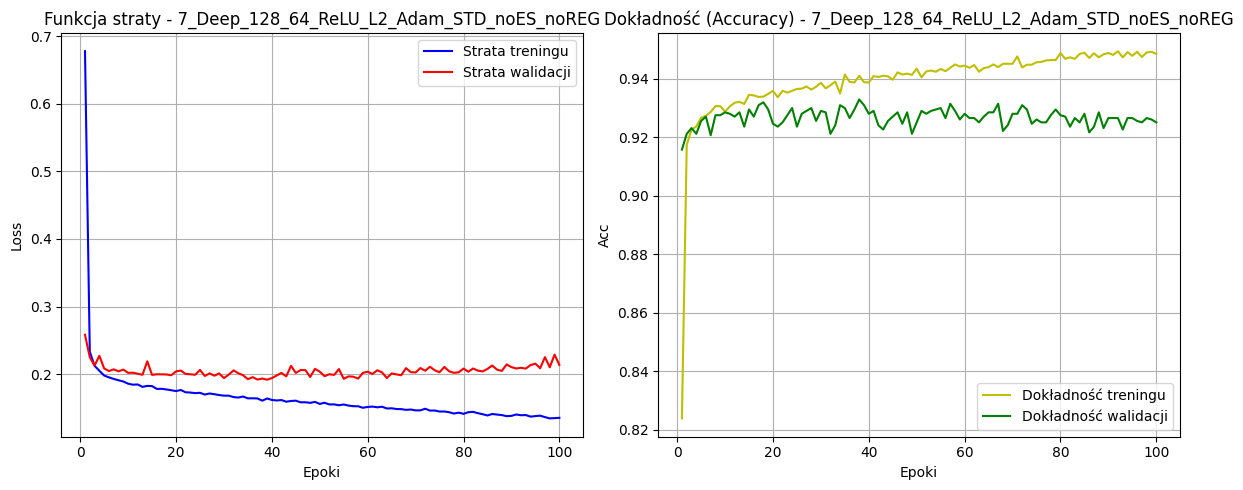

In [70]:
# Wersja tej samej architektury co Model 7, ale bez regularyzacji L2 i bez early stoppingu
best_noreg_model = M7()
best_noreg_name  = best_base_name + "_STD_noES_noREG"

best_noreg_history = train_model_no_early_stopping(
    best_noreg_model,
    best_noreg_name,
    train_loader,
    val_loader,
    opt_type='adam',
    epochs=100,
    lr=0.001,
    wd=0.0          # brak L2
)

plot_training_results(best_noreg_history, best_noreg_name)

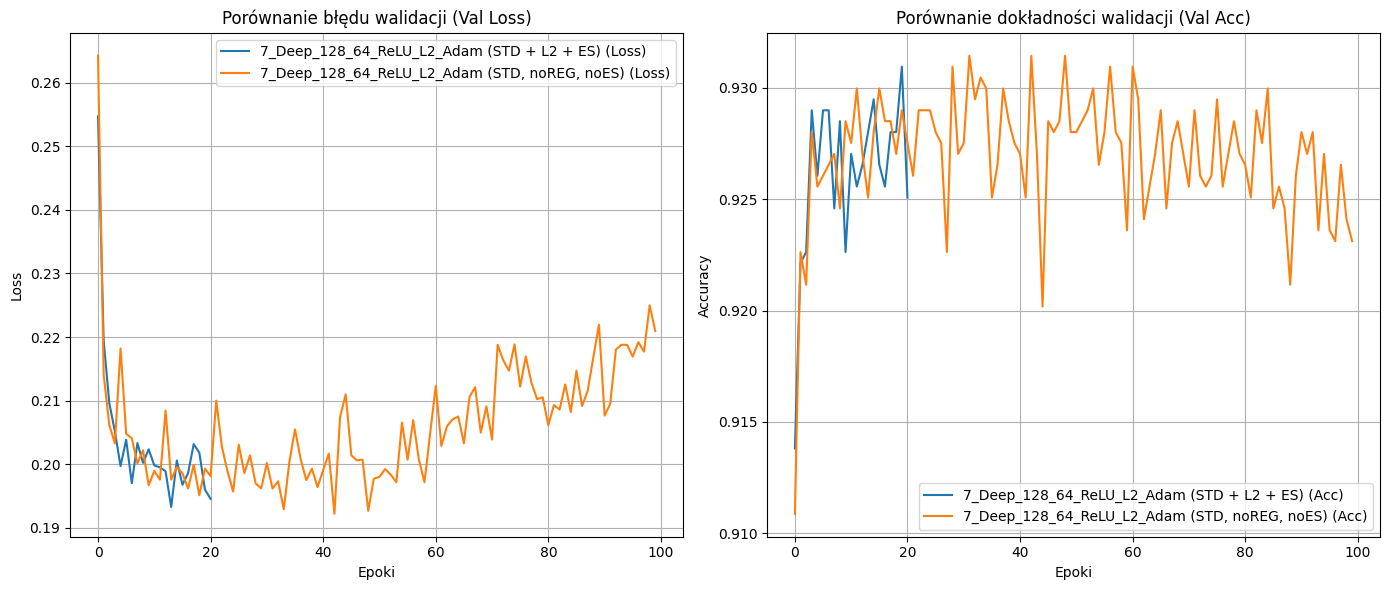

In [25]:
# Porównanie najlepszy Model 7 vs ten sam bez regularizacji i bez early stoppingu
compare_models(
    histories=[best_std_history, best_noreg_history],
    names=[
        best_base_name + " (STD + L2 + ES)",
        best_base_name + " (STD, noREG, noES)"
    ]
)

**Wnioski do eksperymentu 3**

- Oryginalny model 7 na danych **standaryzowanych z regularyzacją i early stoppingiem** (STD + reg/ES) utrzymuje wysoką dokładność walidacyjną bez wyraźnych oznak przeuczenia.  
- Wersja **bez regularyzacji i bez early stoppingu** (STD, noREG, noES) początkowo osiąga podobną dokładność walidaycjną, ale w dalszej części treningu pojawiają się symptomy przeuczenia (wzrost Val Loss przy ciągłym spadku Train Loss oraz spadki jak i duże skoki Val Acc przy rosnącej Train Acc).  
- Wniosek praktyczny: w tym zadaniu regularyzacja (L2) oraz early stopping pomagają ustabilizować trening i poprawić generalizację modelu na nowych danych.

# 6. Porównanie najlepszych modeli na zbiorze testowym


W niniejszej sekcji przeprowadzono ostateczną ewaluację zdolności generalizacji modeli na zbiorze testowym. Do porównania wytypowano po jednym reprezentancie z każdej z ośmiu kategorii architektur. Kryterium wyboru stanowiło osiągnięcie najniższej wartości funkcji straty na zbiorze walidacyjnym, co pozwala na obiektywne zestawienie najbardziej stabilnych wariantów każdej z testowanych konfiguracji.

In [66]:
# 1. Tworzymy listę wszystkich modeli (nazwa, klasa_modelu)
model_list = [
    (m1_name, M1()),
    (m2_name, M1()),
    (m3_name, M3()),
    (m4_name, M4()),
    (m5_name, M5()),
    (m6_name, M6()),
    (m7_name, M7()),
    (m8_name, M8())
]

test_results = []

print("Rozpoczynam ostateczne testowanie wszystkich 8 modeli...")

for name, model_arch in model_list:
    try:
        # Wczytujemy najlepsze wagi dla danego modelu
        model_arch.load_state_dict(torch.load(f'best_model_{name}.pth'))
        model_arch.eval()

        correct = 0
        total = 0

        with torch.no_grad():
            for inputs, targets in test_loader:
                outputs = model_arch(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += targets.size(0)
                correct += (predicted == targets).sum().item()

        acc = correct / total
        test_results.append({'Model': name, 'Test_Acc': acc})
        print(f"Zakończono: {name} | Test Acc: {acc:.4f}")

    except FileNotFoundError:
        print(f"Ostrzeżenie: Nie znaleziono pliku wag dla {name}")

# 2. Tworzymy tabelę zbiorczą
summary_df = pd.DataFrame(test_results)

# 3. Sortujemy wyniki malejąco
summary_df = summary_df.sort_values(by='Test_Acc', ascending=False).reset_index(drop=True)

# Wyświetlamy ranking
print("\nRANKING MODELI (NA ZBIORZE TESTOWYM):")
print(summary_df)

# 4. Wybieramy absolutnego zwycięzcę do Macierzy Pomyłek
best_overall_name = summary_df.iloc[0]['Model']
print(f'\n>>> Zwycięzca testu: {best_overall_name}')

Rozpoczynam ostateczne testowanie wszystkich 8 modeli...
Zakończono: 1_Small_12_ReLU_SGD | Test Acc: 0.8702
Zakończono: 2_Small_12_ReLU_Adam | Test Acc: 0.9202
Zakończono: 3_Med_64_ReLU_Adam | Test Acc: 0.9221
Zakończono: 4_Med_64_Sigmoid_Adam | Test Acc: 0.9216
Zakończono: 5_Med_64_Tanh_Adam | Test Acc: 0.9216
Zakończono: 6_Big_256_Tanh_Adam_Dropout | Test Acc: 0.9216
Zakończono: 7_Deep_128_64_ReLU_L2_Adam | Test Acc: 0.9261
Zakończono: 8_Deep_128_64_32ReLU_Dropout_Adam | Test Acc: 0.9231

RANKING MODELI (NA ZBIORZE TESTOWYM):
                               Model  Test_Acc
0         7_Deep_128_64_ReLU_L2_Adam  0.926053
1  8_Deep_128_64_32ReLU_Dropout_Adam  0.923115
2                 3_Med_64_ReLU_Adam  0.922135
3              4_Med_64_Sigmoid_Adam  0.921645
4        6_Big_256_Tanh_Adam_Dropout  0.921645
5                 5_Med_64_Tanh_Adam  0.921645
6               2_Small_12_ReLU_Adam  0.920176
7                1_Small_12_ReLU_SGD  0.870225

>>> Zwycięzca testu: 7_Deep_128_64_ReLU_L2

# 7. Wizualizacja predykcji najlepszego modelu za pomocą macierzy pomyłek

Najwyższą skutecznością predykcyjną na danych testowych wykazał się model 7_Deep_128_64_ReLU_L2_Adam. W celu pogłębionej interpretacji jakości klasyfikacji oraz identyfikacji tendencji do popełniania błędów między poszczególnymi odmianami fasoli, dla powyższego modelu wygenerowano macierz pomyłek (Confusion Matrix). Analiza ta, stanowi fundament dla sformułowania końcowych wniosków badawczych dotyczących separowalności cech morfologicznych w przestrzeni wielowymiarowej.

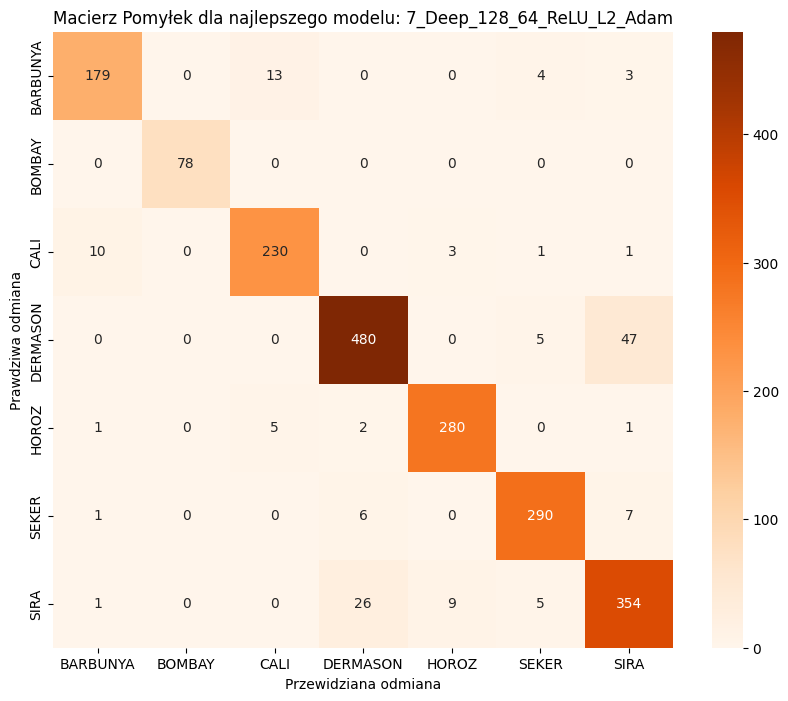


--- ANALIZA SKUTECZNOŚCI DLA: 7_Deep_128_64_ReLU_L2_Adam ---
Odmiana BARBUNYA   | Skuteczność: 89.95%
Odmiana BOMBAY     | Skuteczność: 100.00%
Odmiana CALI       | Skuteczność: 93.88%
Odmiana DERMASON   | Skuteczność: 90.23%
Odmiana HOROZ      | Skuteczność: 96.89%
Odmiana SEKER      | Skuteczność: 95.39%
Odmiana SIRA       | Skuteczność: 89.62%


In [71]:
# 1. Znajdujemy gotowy obiekt modelu (w liście model_list na podstawie nazwy zwycięzcy)
best_model_obj = None
for name, arch in model_list:
    if name == best_overall_name:
        best_model_obj = arch
        break

# 2. Ładowanie wag i tryb ewaluacji
best_model_obj.load_state_dict(torch.load(f'best_model_{best_overall_name}.pth'))
best_model_obj.eval()

y_true = []
y_pred = []

# 3. Zbieranie danych do macierzy na zbiorze testowym
with torch.no_grad():
    for inputs, targets in test_loader:
        outputs = best_model_obj(inputs)
        _, predicted = torch.max(outputs.data, 1)

        y_true.extend(targets.numpy())
        y_pred.extend(predicted.numpy())

# 4. Rysowanie Macierzy Pomyłek
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)

plt.xlabel('Przewidziana odmiana')
plt.ylabel('Prawdziwa odmiana')
plt.title(f'Macierz Pomyłek dla najlepszego modelu: {best_overall_name}')
plt.show()

# 5. Procentowe zestawienie do wniosków w raporcie
print(f"\n--- ANALIZA SKUTECZNOŚCI DLA: {best_overall_name} ---")
for i, class_name in enumerate(encoder.classes_):
    accuracy = 100 * cm[i, i] / sum(cm[i, :])
    print(f"Odmiana {class_name:10} | Skuteczność: {accuracy:.2f}%")

# 8. Analiza fizycznego podobieństwa klas Sira i Dermason

Wychodzimy poza interpretację metryk skuteczności, aby zrozumieć **geometryczne** przyczyny błędów klasyfikacji. Skupiamy się na parze gatunków **Sira oraz Dermason,** które w macierzy pomyłek wykazują najwyższy stopień wzajemnej korelacji. Poprzez zestawienie ich **rozkładów statystycznych** sprawdzimy, w jakim stopniu ich cechy morfologiczne (takie jak pole powierzchni czy smukłość) nakładają się na siebie, tworząc trudną do rozdzielenia strefę dla sieci neuronowej.

In [28]:
# Grupowanie po klasie i wyciągnięcie średnich dla kluczowych cech
analysis = dry_bean.groupby('Class')[['Area', 'AspectRation', 'Solidity']].mean()
print(analysis)

                   Area  AspectRation  Solidity
Class                                          
BARBUNYA   69804.133132      1.544395  0.982804
BOMBAY    173485.059387      1.585550  0.986902
CALI       75538.211043      1.733663  0.985021
DERMASON   32118.710942      1.490471  0.988226
HOROZ      53648.508817      2.026119  0.985480
SEKER      39881.299951      1.245182  0.990351
SIRA       44729.128604      1.570083  0.987971


Podczas gdy klasy takie jak **Bombay** (wyróżniająca się **ekstremalnie dużą powierzchnią**) oraz **Horoz** (charakteryzująca się **unikalną AspectRation** ) są łatwo rozróżnialne przez sieć, gatunki **Sira i Dermason** wykazują niemal identyczne parametry fizyczne, co czyni je najtrudniejszym punktem klasyfikacji.

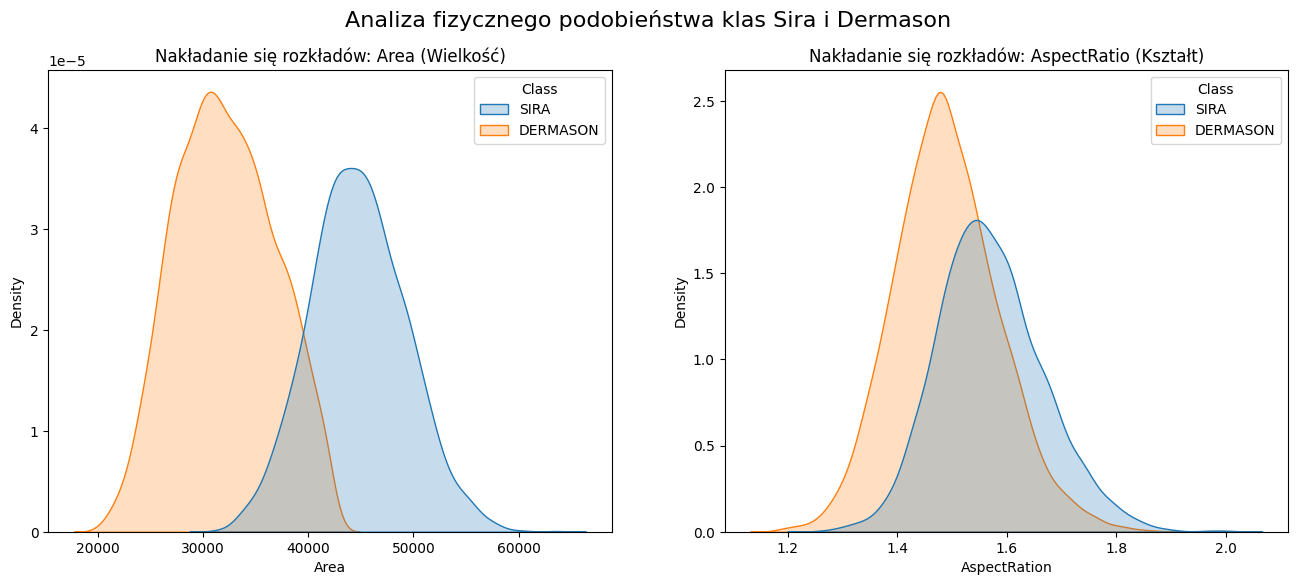

In [29]:
# Filtrowanie danych tylko dla problematycznych klas
overlap_classes = ['SIRA', 'DERMASON']
df_overlap = dry_bean[dry_bean['Class'].isin(overlap_classes)]

# Ustawienie figury dla dwóch kluczowych parametrów
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Porównanie Pola Powierzchni (Area)
sns.kdeplot(data=df_overlap, x='Area', hue='Class', fill=True, ax=axes[0])
axes[0].set_title('Nakładanie się rozkładów: Area (Wielkość)')

# 2. Porównanie Smukłości (AspectRatio)
sns.kdeplot(data=df_overlap, x='AspectRation', hue='Class', fill=True, ax=axes[1])
axes[1].set_title('Nakładanie się rozkładów: AspectRatio (Kształt)')

plt.suptitle('Analiza fizycznego podobieństwa klas Sira i Dermason', fontsize=16)
plt.show()

**Przyczyny trudności klasyfikacyjnych**
* **Nakładanie się rozkładów:** Jak widać na powyższych wykresach gęstości, krzywe dla Sira i Dermason się pokrywają. Różnica w średnim polu powierzchni często wynosi mniej niż 5-10%, co sprawia, że ziarna o tych samych wymiarach mogą należeć do obu gatunków jednocześnie.

* **Brak cechy unikalnej:** W przeciwieństwie do klasy Bombay (która jest gigantyczna) czy Horoz (która jest bardzo podłużna), Sira i Dermason nie posiadają żadnej wiodącej cechy geometrycznej, która by je jednoznacznie rozdzielała.

# 9. Wnioski końcowe i analiza wyników

Ostateczny zwycięski model **7_Deep_128_64_ReLU_L2_Adam** osiągnął dokładność na poziomie **92,61%** na zbiorze testowym. Jest to bardzo dobry wynik, biorąc pod uwagę, że zadanie obejmuje klasyfikację **7 odmian fasoli** na podstawie samych cech geometrycznych.

Model ten okazał się najlepszy spośród osmiu finalnie porównywanych architektur:

- **7_Deep_128_64_ReLU_L2_Adam** — **92,61%**,
- **8_Deep_128_64_32ReLU_Dropout_Adam** — **92,31%**,
- **3_Med_64_ReLU_Adam** — **92,21%**,
- **4_Med_64_Sigmoid_Adam** — **92,16%**,
- **6_Big_256_Tanh_Adam_Dropout** — **92,16%**,
- **5_Med_64_Tanh_Adam** — **92,16%**,
- **2_Small_12_ReLU_Adam** — **92,02%**,
- **1_Small_12_ReLU_SGD** — **87,02%**.

Oznacza to, że nie największa ani najgłębsza sieć była najlepsza, lecz model o umiarkowanej głębokości, z dwiema warstwami ukrytymi, aktywacją ReLU i regularyzacją L2.

## Kluczowe obserwacje eksperymentalne

1. **Architektura sieci: najlepszy kompromis między pojemnością a generalizacją**  
   Model 7 z dwiema warstwami ukrytymi okazał się lepszy od szerszego modelu 6 i głębszego modelu 8.  
   Sugeruje to, że dla tego zbioru danych zbyt duża pojemność modelu nie daje już zysku, a może wręcz utrudniać generalizację.

2. **Funkcja aktywacji: skuteczność ReLU na danych ze standaryzacją**  
   W finalnym zwycięzcy zastosowano **ReLU**, która dobrze współpracuje ze standaryzowanymi danymi i pozwala na stabilne uczenie głębszej sieci.  
   W tym eksperymencie ReLU okazała się bardziej korzystna niż bardziej „gładkie” warianty, takie jak Tanh, dla końcowego modelu testowego.

3. **Regularyzacja: istotna rola L2**  
   Zastosowanie **L2** w modelu 7 pomogło ograniczyć przeuczenie i poprawiło zdolność modelu do generalizacji.  
   To potwierdza, że dla tego zadania sama większa liczba parametrów nie wystarcza — ważne jest także kontrolowanie złożoności modelu.

4. **Early stopping jako element kontroli treningu**  
   W trakcie uczenia najlepszych modeli obserwowano sytuację, w której walidacyjna funkcja straty przestawała się poprawiać mimo dalszego spadku straty treningowej.  
   Early stopping pozwalał zatrzymać trening w korzystnym momencie i ograniczyć ryzyko przeuczenia.

## Analiza macierzy pomyłek

Macierz pomyłek dla najlepszego modelu pokazuje, że klasyfikacja większości odmian została wykonana bardzo dobrze, a błędy koncentrują się głównie między odmianami **Dermason** i **Sira** (ich dokładniejsza analiza została przeprowadzona w poprzednim rozdziale) oraz częściowo między **Barbunya** i **Cali**.

### Najważniejsze obserwacje z macierzy:
- **Bombay** został rozpoznany perfekcyjnie: **78/78** poprawnych klasyfikacji.
- **Dermason** i **Sira** stanowią najtrudniejszy duet:
  - część ziaren Dermason została zaklasyfikowana jako Sira,
  - część ziaren Sira została zaklasyfikowana jako Dermason.
- **Barbunya** również bywa mylona z **Cali**, ale skala błędu jest mniejsza niż w przypadku Dermason i Sira.

Taki układ błędów sugeruje, że niektóre odmiany fasoli mają bardzo podobne cechy geometryczne i są trudne do rozdzielenia nawet dla dobrze wytrenowanej sieci neuronowej.

## Wpływ standaryzacji

Standaryzacja cech okazała się bardzo ważna dla jakości działania modeli.  
Dane przeskalowane do podobnego zakresu pozwoliły sieci szybciej i stabilniej się uczyć, co przełożyło się na lepsze wyniki końcowe.

Porównanie z wariantem bez standaryzacji pokazało, że preprocessing ma realny wpływ na skuteczność klasyfikacji.  
W przypadku tego zadania standaryzacja była jednym z kluczowych elementów poprawiających działanie modelu.

## Wnioski końcowe

Najlepszym rozwiązaniem okazał się model **7_Deep_128_64_ReLU_L2_Adam**, ponieważ zapewnił najwyższą skuteczność na zbiorze testowym i bardzo dobrą równowagę między złożonością a generalizacją.

Eksperyment pokazał, że:
- zbyt małe modele mają ograniczoną zdolność reprezentowania danych (w wynikach na zbiorze testowym zajmują dwa ostatnie miejsca),
- zbyt duże modele nie muszą dawać lepszych wyników,
- regularyzacja i standaryzacja są kluczowe dla stabilnego uczenia,
- wybór architektury powinien wynikać nie tylko z liczby warstw, ale też z zachowania na zbiorze walidacyjnym i testowym.

Ostatecznie projekt potwierdził, że dobrze dobrana, umiarkowanie złożona sieć neuronowa może skutecznie rozwiązywać zadanie wieloklasowej klasyfikacji danych morfologicznych.